# Baseline Random Forest 모델
## 캡스톤디자인 I — 특징 추출 최적화 기반 암호화된 공격 트래픽 탐지 및 분류 시스템

**실험 목적:** 특징 추출 전후 성능 비교
- CIC-IDS2017: 전처리 완료본(68개) vs 특징 추출 완료본(32개)
- Malicious_TLS: 전처리 완료본(117개) vs 특징 추출 완료본(68개)

## 0. 구글 드라이브 마운트

In [4]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 1. 라이브러리 및 경로 설정

In [5]:
import pandas as pd
import numpy as np
import time
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'DejaVu Sans'

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report, accuracy_score,
    confusion_matrix, ConfusionMatrixDisplay, f1_score
)
from sklearn.preprocessing import LabelEncoder

BASE = '/content/drive/MyDrive/capstone2026'

# 경로 정의
PATHS = {
    'cic_full':     f'{BASE}/output/cleansing/cicids2017_cleaned_v2.csv',
    'cic_feat':     f'{BASE}/output/features/CIC-IDS2017/cicids2017_features_final.csv',
    'cic_sel':      f'{BASE}/output/features/CIC-IDS2017/cicids2017_selected_features.txt',
    'tls_full':     f'{BASE}/output/cleansing/malicious_tls_cleaned.csv',
    'tls_feat':     f'{BASE}/output/features/Malicious_TLS/malicious_tls_features_final.csv',
    'tls_sel':      f'{BASE}/output/features/Malicious_TLS/malicious_tls_selected_features.txt',
}

print('경로 설정 완료')

경로 설정 완료


In [6]:
import subprocess
subprocess.run(['apt-get', 'install', '-y', 'fonts-nanum'], capture_output=True)

import matplotlib as mpl
import matplotlib.font_manager as fm
import os

# 캐시 삭제
cache_dir = mpl.get_cachedir()
for f in os.listdir(cache_dir):
    if f.endswith('.json') or f.endswith('.cache'):
        os.remove(os.path.join(cache_dir, f))

# 폰트 등록
font_path = '/usr/share/fonts/truetype/nanum/NanumGothic.ttf'
fm.fontManager.addfont(font_path)
fm._load_fontmanager(try_read_cache=False)

import matplotlib.pyplot as plt
plt.rcParams['font.family'] = 'NanumGothic'
plt.rcParams['axes.unicode_minus'] = False

print([f.name for f in fm.fontManager.ttflist if 'Nanum' in f.name])
print('폰트 설정 완료')

['NanumGothic', 'NanumGothic']
폰트 설정 완료


## 2. 데이터 로드 확인

In [7]:
# CIC-IDS2017
print('=== CIC-IDS2017 로드 중... ===')
df_cic_full = pd.read_csv(PATHS['cic_full'], low_memory=False)
df_cic_feat = pd.read_csv(PATHS['cic_feat'], low_memory=False)
with open(PATHS['cic_sel']) as f:
    cic_selected = [line.strip() for line in f if line.strip()]

print(f'전처리 완료본: {df_cic_full.shape}')
print(f'특징 추출 완료본: {df_cic_feat.shape}')
print(f'선택 특징 수: {len(cic_selected)}개')
print(f'레이블 분포:\n{df_cic_feat["Label"].value_counts()}\n')

# Malicious_TLS
print('=== Malicious_TLS 로드 중... ===')
df_tls_full = pd.read_csv(PATHS['tls_full'], low_memory=False)
df_tls_feat = pd.read_csv(PATHS['tls_feat'], low_memory=False)
with open(PATHS['tls_sel']) as f:
    tls_selected = [line.strip() for line in f if line.strip()]

print(f'전처리 완료본: {df_tls_full.shape}')
print(f'특징 추출 완료본: {df_tls_feat.shape}')
print(f'선택 특징 수: {len(tls_selected)}개')
print(f'레이블 분포:\n{df_tls_feat["Label"].value_counts()}')

=== CIC-IDS2017 로드 중... ===
전처리 완료본: (2824888, 69)
특징 추출 완료본: (2824888, 33)
선택 특징 수: 32개
레이블 분포:
Label
BENIGN                      2268589
DoS Hulk                     229965
PortScan                     158804
DDoS                         128006
DoS GoldenEye                 10288
FTP-Patator                    7931
SSH-Patator                    5895
DoS slowloris                  5796
DoS Slowhttptest               5499
Bot                            1956
Web Attack - Brute Force       1507
Web Attack - XSS                652
Name: count, dtype: int64

=== Malicious_TLS 로드 중... ===
전처리 완료본: (90925, 118)
특징 추출 완료본: (90925, 69)
선택 특징 수: 68개
레이블 분포:
Label
benign                            33213
burpsuite_burpsuite_TLS_scan       4798
Vawtrak.C_None_TLS_CC              3283
Tiggre_None_TLS_CC                 3266
Shifu.A_None_TLS_CC                3255
Tor_None_TLS_CC                    3182
Caphaw.A_None_TLS_CC               3124
Caphaw.AH_None_TLS_CC              3062
Drixed_None_TLS_

## 3. 공통 함수 정의

In [9]:
def run_rf(df, feature_cols, label_col='Label', n_estimators=100, label_name='실험'):
    """
    Random Forest 학습 및 평가
    Returns: dict (결과 요약)
    """
    # 특징/레이블 분리
    X = df[feature_cols].copy()
    y = df[label_col].copy()

    # 레이블 인코딩
    le = LabelEncoder()
    y_enc = le.fit_transform(y)

    # 학습/테스트 분할 (80:20, stratified)
    X_train, X_test, y_train, y_test = train_test_split(
        X, y_enc, test_size=0.2, random_state=42, stratify=y_enc
    )

    # 모델 학습
    print(f'\n[{label_name}] 학습 시작... (특징 {len(feature_cols)}개, 학습 {len(X_train):,}행)')
    t0 = time.time()
    clf = RandomForestClassifier(
        n_estimators=n_estimators,
        random_state=42,
        n_jobs=-1,
        class_weight='balanced'
    )
    clf.fit(X_train, y_train)
    train_time = time.time() - t0

    # 평가
    y_pred = clf.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    f1_macro = f1_score(y_test, y_pred, average='macro')
    f1_weighted = f1_score(y_test, y_pred, average='weighted')

    print(f'학습 시간: {train_time:.1f}초')
    print(f'Accuracy:    {acc:.4f} ({acc*100:.2f}%)')
    print(f'F1 (macro):  {f1_macro:.4f}')
    print(f'F1 (weighted): {f1_weighted:.4f}')
    print('\n분류 보고서:')
    print(classification_report(y_test, y_pred, target_names=le.classes_))

    return {
        'label_name': label_name,
        'n_features': len(feature_cols),
        'accuracy': acc,
        'f1_macro': f1_macro,
        'f1_weighted': f1_weighted,
        'train_time': train_time,
        'clf': clf,
        'le': le,
        'X_test': X_test,
        'y_test': y_test,
        'y_pred': y_pred,
        'feature_cols': feature_cols
    }

print('함수 정의 완료')

함수 정의 완료


## 4. CIC-IDS2017 실험

In [10]:
# 전처리 완료본 특징 컬럼 (Label 제외)
cic_full_cols = [c for c in df_cic_full.columns if c != 'Label']

# 실험 A: 특징 추출 전 (전체 특징)
result_cic_before = run_rf(
    df_cic_full, cic_full_cols,
    label_name='CIC-IDS2017 특징추출 전'
)


[CIC-IDS2017 특징추출 전] 학습 시작... (특징 68개, 학습 2,259,910행)
학습 시간: 915.0초
Accuracy:    0.9986 (99.86%)
F1 (macro):  0.8996
F1 (weighted): 0.9986

분류 보고서:
                          precision    recall  f1-score   support

                  BENIGN       1.00      1.00      1.00    453718
                     Bot       0.84      0.75      0.79       391
                    DDoS       1.00      1.00      1.00     25601
           DoS GoldenEye       1.00      0.99      1.00      2058
                DoS Hulk       1.00      1.00      1.00     45993
        DoS Slowhttptest       0.95      0.99      0.97      1100
           DoS slowloris       1.00      0.99      0.99      1159
             FTP-Patator       1.00      1.00      1.00      1586
                PortScan       0.99      1.00      1.00     31761
             SSH-Patator       1.00      0.99      1.00      1179
Web Attack - Brute Force       0.72      0.81      0.76       302
        Web Attack - XSS       0.40      0.22      0.29   

In [11]:
# 실험 B: 특징 추출 후 (32개 선택)
# selected_features.txt에 있는 특징명이 df_cic_feat 컬럼과 일치하는지 확인
available = [c for c in cic_selected if c in df_cic_feat.columns]
missing   = [c for c in cic_selected if c not in df_cic_feat.columns]
if missing:
    print(f'⚠️ 누락 특징: {missing}')

result_cic_after = run_rf(
    df_cic_feat, available,
    label_name='CIC-IDS2017 특징추출 후'
)


[CIC-IDS2017 특징추출 후] 학습 시작... (특징 32개, 학습 2,259,910행)
학습 시간: 667.5초
Accuracy:    0.9986 (99.86%)
F1 (macro):  0.8975
F1 (weighted): 0.9985

분류 보고서:
                          precision    recall  f1-score   support

                  BENIGN       1.00      1.00      1.00    453718
                     Bot       0.84      0.74      0.79       391
                    DDoS       1.00      1.00      1.00     25601
           DoS GoldenEye       1.00      0.99      0.99      2058
                DoS Hulk       1.00      1.00      1.00     45993
        DoS Slowhttptest       0.95      0.99      0.97      1100
           DoS slowloris       1.00      0.99      0.99      1159
             FTP-Patator       1.00      1.00      1.00      1586
                PortScan       0.99      1.00      1.00     31761
             SSH-Patator       1.00      0.99      1.00      1179
Web Attack - Brute Force       0.72      0.81      0.76       302
        Web Attack - XSS       0.38      0.22      0.27   

## 5. Malicious_TLS 실험

In [12]:
# 전처리 완료본 특징 컬럼
tls_full_cols = [c for c in df_tls_full.columns if c != 'Label']

# 실험 A: 특징 추출 전
result_tls_before = run_rf(
    df_tls_full, tls_full_cols,
    label_name='Malicious_TLS 특징추출 전'
)


[Malicious_TLS 특징추출 전] 학습 시작... (특징 117개, 학습 72,740행)
학습 시간: 25.7초
Accuracy:    0.9903 (99.03%)
F1 (macro):  0.9847
F1 (weighted): 0.9902

분류 보고서:
                                precision    recall  f1-score   support

            Banker_None_TLS_CC       1.00      0.99      1.00       356
        BuerLoader_None_TLS_CC       1.00      1.00      1.00       597
         Caphaw.AH_None_TLS_CC       0.92      0.88      0.90       612
          Caphaw.A_None_TLS_CC       0.88      0.93      0.91       625
      CobaltStrike_None_TLS_CC       1.00      1.00      1.00       590
          DridexCC_None_TLS_CC       0.99      1.00      0.99       575
            Drixed_None_TLS_CC       1.00      1.00      1.00       599
        Dynamer!ac_None_TLS_CC       1.00      1.00      1.00       453
      Panda.BZA!tr_None_TLS_CC       0.97      0.88      0.92       263
       PandaZeuSCC_None_TLS_CC       0.95      0.99      0.97       556
            Qakbot_None_TLS_CC       1.00      1.00      1.

In [13]:
# 실험 B: 특징 추출 후 (68개 선택)
tls_available = [c for c in tls_selected if c in df_tls_feat.columns]
tls_missing   = [c for c in tls_selected if c not in df_tls_feat.columns]
if tls_missing:
    print(f'⚠️ 누락 특징: {tls_missing}')

result_tls_after = run_rf(
    df_tls_feat, tls_available,
    label_name='Malicious_TLS 특징추출 후'
)


[Malicious_TLS 특징추출 후] 학습 시작... (특징 68개, 학습 72,740행)
학습 시간: 18.5초
Accuracy:    0.9911 (99.11%)
F1 (macro):  0.9863
F1 (weighted): 0.9911

분류 보고서:
                                precision    recall  f1-score   support

            Banker_None_TLS_CC       1.00      0.99      1.00       356
        BuerLoader_None_TLS_CC       1.00      1.00      1.00       597
         Caphaw.AH_None_TLS_CC       0.93      0.88      0.90       612
          Caphaw.A_None_TLS_CC       0.89      0.94      0.91       625
      CobaltStrike_None_TLS_CC       1.00      1.00      1.00       590
          DridexCC_None_TLS_CC       0.99      0.99      0.99       575
            Drixed_None_TLS_CC       1.00      1.00      1.00       599
        Dynamer!ac_None_TLS_CC       1.00      1.00      1.00       453
      Panda.BZA!tr_None_TLS_CC       0.98      0.89      0.93       263
       PandaZeuSCC_None_TLS_CC       0.95      0.99      0.97       556
            Qakbot_None_TLS_CC       1.00      1.00      1.0

## 6. 특징 추출 전후 비교 시각화

=== 특징 추출 전후 비교 요약 ===
                  실험  특징 수 Accuracy F1 (macro) F1 (weighted) 학습 시간(초)
  CIC-IDS2017 특징추출 전    68   99.86%     0.8996        0.9986    786.4
  CIC-IDS2017 특징추출 후    32   99.86%     0.8975        0.9985    655.1
Malicious_TLS 특징추출 전   117   99.03%     0.9847        0.9902     27.8
Malicious_TLS 특징추출 후    68   99.11%     0.9863        0.9911     18.9


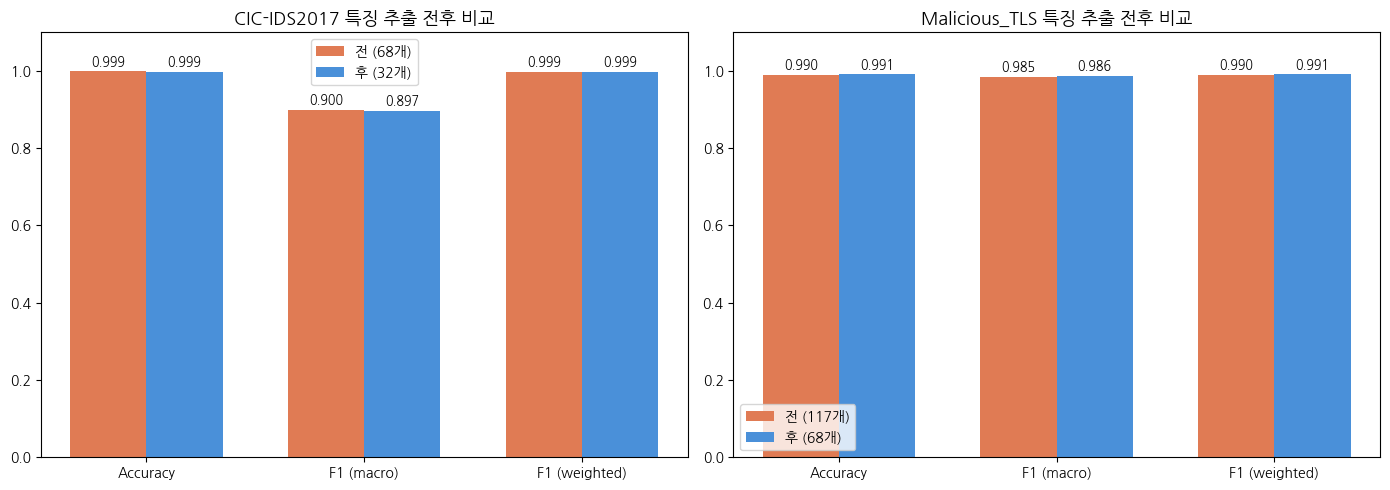

그래프 저장 완료: output/RF/baseline_rf_comparison.png


In [ ]:
results = [
    result_cic_before,
    result_cic_after,
    result_tls_before,
    result_tls_after,
]

# 요약 테이블
summary = pd.DataFrame([{
    '실험': r['label_name'],
    '특징 수': r['n_features'],
    'Accuracy': f"{r['accuracy']*100:.2f}%",
    'F1 (macro)': f"{r['f1_macro']:.4f}",
    'F1 (weighted)': f"{r['f1_weighted']:.4f}",
    '학습 시간(초)': f"{r['train_time']:.1f}"
} for r in results])

print('=== 특징 추출 전후 비교 요약 ===')
print(summary.to_string(index=False))

# 막대 그래프
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, (before, after, title) in zip(axes, [
    (result_cic_before, result_cic_after, 'CIC-IDS2017'),
    (result_tls_before, result_tls_after, 'Malicious_TLS'),
]):
    metrics = ['Accuracy', 'F1 (macro)', 'F1 (weighted)']
    before_vals = [before['accuracy'], before['f1_macro'], before['f1_weighted']]
    after_vals  = [after['accuracy'],  after['f1_macro'],  after['f1_weighted']]

    x = np.arange(len(metrics))
    width = 0.35
    bars1 = ax.bar(x - width/2, before_vals, width, label=f'전 ({before["n_features"]}개)', color='#E07B54')
    bars2 = ax.bar(x + width/2, after_vals,  width, label=f'후 ({after["n_features"]}개)',  color='#4A90D9')

    ax.set_title(f'{title} 특징 추출 전후 비교', fontsize=13)
    ax.set_xticks(x)
    ax.set_xticklabels(metrics)
    ax.set_ylim(0, 1.1)
    ax.legend()
    ax.bar_label(bars1, fmt='%.3f', padding=2, fontsize=9)
    ax.bar_label(bars2, fmt='%.3f', padding=2, fontsize=9)

plt.tight_layout()
plt.savefig(f'{BASE}/output/RF/baseline_rf_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print('그래프 저장 완료: output/RF/baseline_rf_comparison.png')

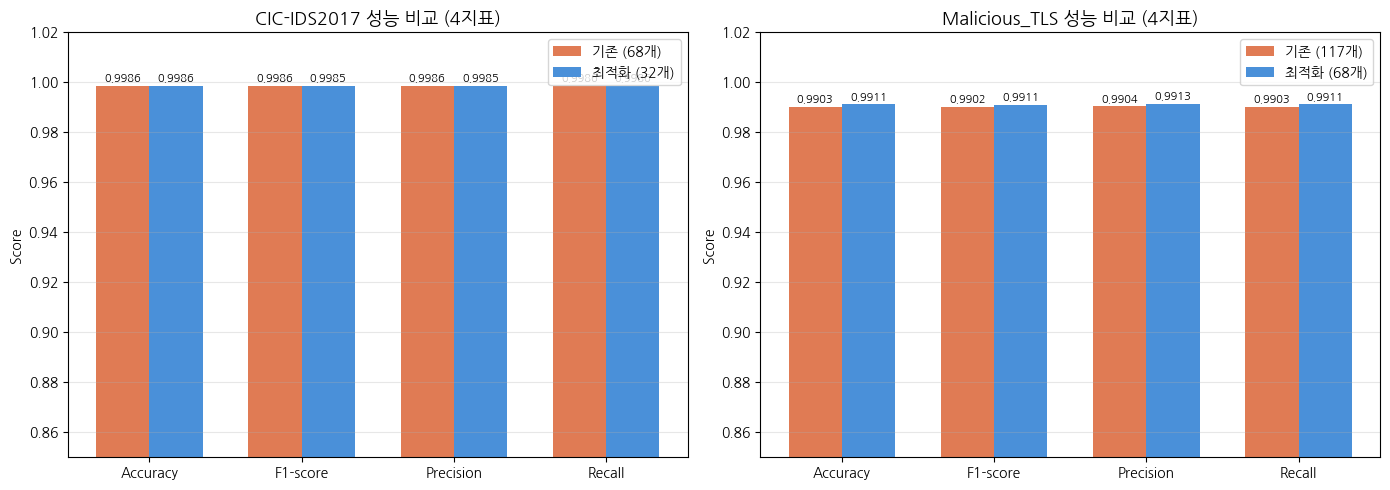

저장 완료: output/RF/baseline_rf_comparison_4metrics.png


In [14]:
from sklearn.metrics import precision_score, recall_score
import matplotlib.font_manager as fm
import matplotlib as mpl
import os

# 한글 폰트 설정
cache_dir = mpl.get_cachedir()
for f in os.listdir(cache_dir):
    if f.endswith('.json') or f.endswith('.cache'):
        os.remove(os.path.join(cache_dir, f))
font_path = '/usr/share/fonts/truetype/nanum/NanumGothic.ttf'
fm.fontManager.addfont(font_path)
fm._load_fontmanager(try_read_cache=False)
plt.rcParams['font.family'] = 'NanumGothic'
plt.rcParams['axes.unicode_minus'] = False

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, (before, after, title) in zip(axes, [
    (result_cic_before, result_cic_after, 'CIC-IDS2017'),
    (result_tls_before, result_tls_after, 'Malicious_TLS'),
]):
    metrics_vals = {}
    for label, result in [('기존', before), ('최적화', after)]:
        metrics_vals[label] = {
            'Accuracy':  accuracy_score(result['y_test'], result['y_pred']),
            'F1-score':  f1_score(result['y_test'], result['y_pred'], average='weighted'),
            'Precision': precision_score(result['y_test'], result['y_pred'], average='weighted', zero_division=0),
            'Recall':    recall_score(result['y_test'], result['y_pred'], average='weighted', zero_division=0),
        }

    metric_names = ['Accuracy', 'F1-score', 'Precision', 'Recall']
    x = np.arange(len(metric_names))
    width = 0.35

    n_feat_before = before['n_features']
    n_feat_after  = after['n_features']

    bars1 = ax.bar(x - width/2, [metrics_vals['기존'][m]  for m in metric_names], width, label=f'기존 ({n_feat_before}개)',   color='#E07B54')
    bars2 = ax.bar(x + width/2, [metrics_vals['최적화'][m] for m in metric_names], width, label=f'최적화 ({n_feat_after}개)', color='#4A90D9')

    ax.set_title(f'{title} 성능 비교 (4지표)', fontsize=13)
    ax.set_xticks(x)
    ax.set_xticklabels(metric_names)
    ax.set_ylim(0.85, 1.02)   # 차이가 잘 보이도록 y축 범위 좁힘
    ax.set_ylabel('Score')
    ax.legend()
    ax.bar_label(bars1, fmt='%.4f', padding=2, fontsize=8)
    ax.bar_label(bars2, fmt='%.4f', padding=2, fontsize=8)
    ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig(f'{BASE}/output/RF/baseline_rf_comparison_4metrics.png', dpi=150, bbox_inches='tight')
plt.show()
print('저장 완료: output/RF/baseline_rf_comparison_4metrics.png')

## 7. Confusion Matrix

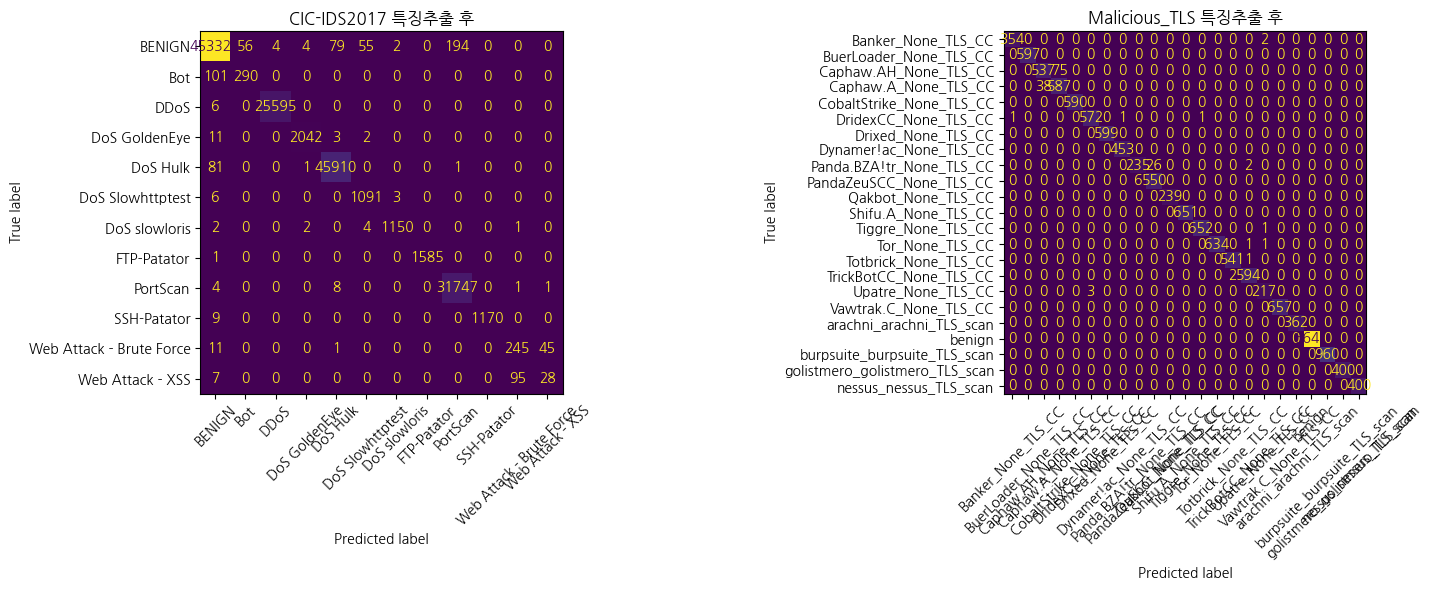

Confusion Matrix 저장 완료


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for ax, result in zip(axes, [result_cic_after, result_tls_after]):
    cm = confusion_matrix(result['y_test'], result['y_pred'])
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=result['le'].classes_
    )
    disp.plot(ax=ax, colorbar=False, xticks_rotation=45)
    ax.set_title(result['label_name'], fontsize=12)

plt.tight_layout()
plt.savefig(f'{BASE}/output/RF/baseline_rf_confusion.png', dpi=150, bbox_inches='tight')
plt.show()
print('Confusion Matrix 저장 완료')

## 8. 결과 요약 저장

In [ ]:
summary.to_csv(f'{BASE}/output/RF/baseline_rf_summary.csv', index=False, encoding='utf-8-sig')
print('결과 저장 완료: output/RF/baseline_rf_summary.csv')
print('\n=== 최종 결과 ===')
print(summary.to_string(index=False))

결과 저장 완료: output/RF/baseline_rf_summary.csv

=== 최종 결과 ===
                  실험  특징 수 Accuracy F1 (macro) F1 (weighted) 학습 시간(초)
  CIC-IDS2017 특징추출 전    68   99.86%     0.8996        0.9986    786.4
  CIC-IDS2017 특징추출 후    32   99.86%     0.8975        0.9985    655.1
Malicious_TLS 특징추출 전   117   99.03%     0.9847        0.9902     27.8
Malicious_TLS 특징추출 후    68   99.11%     0.9863        0.9911     18.9
